In [114]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

In [115]:
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from src.config import load_yaml_config
from src.data import download_data, load_data_from_json
from src.plotting import plot_R_m, plot_C_24

config = load_yaml_config(project_root / "config.yaml")
city = "Lisboa"

In [116]:
# Download data if it isn't already downloaded
download_data(city, config)

HTTP status: 200
Request URL: https://archive-api.open-meteo.com/v1/archive?latitude=38.7223&longitude=-9.1393&start_date=2020-01-01&end_date=2025-12-31&hourly=temperature_2m%2Crelative_humidity_2m%2Cprecipitation%2Cwind_speed_10m&timezone=Europe%2FLisbon


In [117]:
# Load data into a DataFrame
df = load_data_from_json(city, config)

In [118]:
# Get the information of all data types present in the DataFrame
# With 52608 entries, we can check if there any null values in any existing column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 52608 entries, 0 to 52607
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  52608 non-null  datetime64[us]
 1   temperature_2m        52608 non-null  float64       
 2   relative_humidity_2m  52608 non-null  int64         
 3   precipitation         52608 non-null  float64       
 4   wind_speed_10m        52608 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1)
memory usage: 2.0 MB


In [119]:
df.describe()

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
count,52608,52608.000000,52608.000000,52608.000000,52608.000000
mean,2022-12-31 23:30:00,17.275540,74.434877,0.074584,12.731623
min,2020-01-01 00:00:00,1.500000,14.000000,0.000000,0.000000
25%,2021-07-01 23:45:00,13.600000,63.000000,0.000000,7.800000
50%,2022-12-31 23:30:00,16.900000,78.000000,0.000000,12.000000
75%,2024-07-01 23:15:00,20.200000,89.000000,0.000000,16.700000
max,2025-12-31 23:00:00,40.700000,100.000000,19.200000,48.800000
std,NaN,5.285831,17.044434,0.437635,6.400850


In [120]:
# Check basic duplicated data
df.duplicated().sum()

np.int64(0)

In [121]:
# Create the rain event
df["rain_event"] = (df["precipitation"] >= 0.1).astype(int)

# Count the occurences of rain event
df["rain_event"].value_counts()

rain_event
0    46260
1     6348
Name: count, dtype: int64

In [122]:
# Check percentage of expected rain event
df["rain_event"].value_counts(normalize=True)

rain_event
0    0.879334
1    0.120666
Name: proportion, dtype: float64

In [123]:
def check_hourly_continuity(df):
    timestamps = (
        pd.to_datetime(df["time"])
        .sort_values()
        .reset_index(drop=True)
    )
    
    differences = timestamps.diff()
    
    irregular = differences[
        differences.notna() &
        (differences != pd.Timedelta(hours=1))
    ]
    
    print(f"Number of observations: {len(timestamps)}")
    print(f"Duplicate timestamps: {timestamps.duplicated().sum()}")
    print(f"Non-hourly transistions: {len(irregular)}")
    
    if irregular.empty:
        print("The stream is continuous at hourly intervals.")
    else:
        print("\nIrregular transitions:")
        for i in irregular.index:
            print(
                f"{timestamps.iloc[i-1]} ->"
                f"{timestamps.iloc[i]} "
                f"[{differences.iloc[i]}]"
            )

check_hourly_continuity(df)

Number of observations: 52608
Duplicate timestamps: 0
Non-hourly transistions: 0
The stream is continuous at hourly intervals.


In [124]:
# Check the humidity where rain_events  == 1
df_rain_events = df[df["rain_event"] == 1]

df_rain_events.describe()

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,rain_event
count,6348,6348.00000,6348.000000,6348.000000,6348.000000,6348.0
mean,2023-02-15 04:28:16.219281,16.22678,84.485192,0.618100,17.213815,1.0
min,2020-01-02 19:00:00,7.10000,40.000000,0.100000,0.400000,1.0
25%,2021-04-28 14:45:00,14.10000,78.000000,0.100000,11.775000,1.0
50%,2023-01-19 22:30:00,16.00000,88.000000,0.200000,16.700000,1.0
75%,2024-10-11 18:15:00,18.40000,93.000000,0.600000,22.400000,1.0
max,2025-12-28 03:00:00,29.90000,100.000000,19.200000,48.800000,1.0
std,NaN,3.18714,10.510355,1.118679,7.627785,0.0


In [125]:
proportion_rain_above_50_humidity = (
    df_rain_events["relative_humidity_2m"] >= 50
).mean()

print(proportion_rain_above_50_humidity)

0.998109640831758


In [126]:
plot_C_24(config, df, city)

Saved /home/yoru/Documents/novaims/Y1/S1/DSM/Practical_Assessments/Data-Stream-Mining-Practical-Assignment-1/temp/Lisboa_C_24_jys1q9do.pdf


In [127]:
c24 = df["rainy_hours_previous_24h"].dropna()

c24.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

count    52584.000000
mean         2.897307
std          4.964552
min          0.000000
25%          0.000000
50%          0.000000
75%          4.000000
90%         10.000000
95%         15.000000
99%         21.000000
max         24.000000
Name: rainy_hours_previous_24h, dtype: float64

## Temporal and operational rain patterns

These checks complement the event-rate and 24-hour-window summaries. Episode duration and time-of-week patterns can help translate the weather stream into tour-scheduling risk.

In [128]:
# Monthly event rates, using the same helper and definition as the Porto analysis.
plot_R_m(config, df, city)

Saved /home/yoru/Documents/novaims/Y1/S1/DSM/Practical_Assessments/Data-Stream-Mining-Practical-Assignment-1/temp/Lisboa_R_m_532vi71w.pdf


In [129]:
# Consecutive rain-event hours form an episode; report durations in hours.
run_id = df["rain_event"].ne(df["rain_event"].shift()).cumsum()
rain_episode_hours = (
    df.loc[df["rain_event"].eq(1)]
      .groupby(run_id)
      .size()
)

print(f"Rain episodes: {len(rain_episode_hours):,}")
print(f"Mean duration: {rain_episode_hours.mean():.2f} hours")
print(f"Median duration: {rain_episode_hours.median():.0f} hours")
print(f"90th percentile duration: {rain_episode_hours.quantile(0.90, interpolation='higher'):.0f} hours")
print(f"Longest episode: {rain_episode_hours.max():.0f} hours")

Rain episodes: 1,696
Mean duration: 3.74 hours
Median duration: 2 hours
90th percentile duration: 8 hours
Longest episode: 36 hours


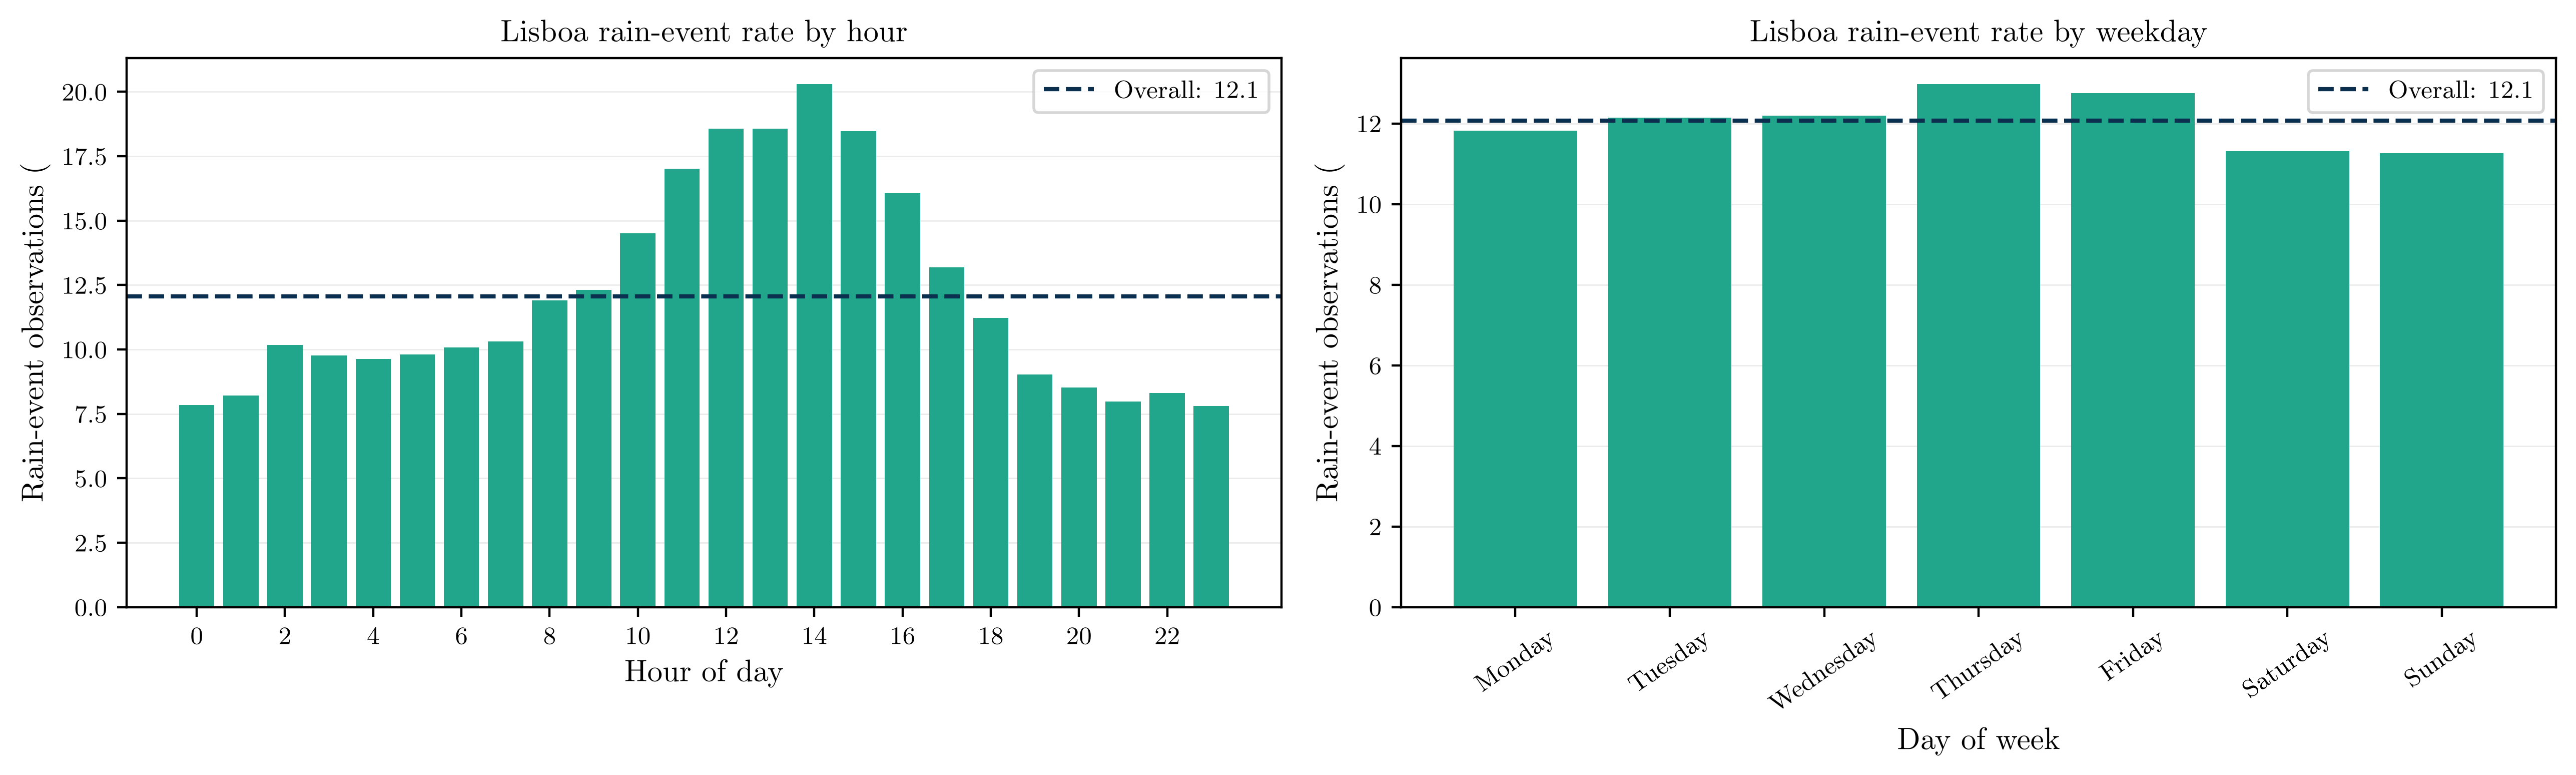

Overall rain-event rate: 12.07%
Highest-risk hour: 14 (20.30%)
Highest-risk weekday: Thursday (12.98%)


In [130]:
# Compare historical event rates by hour and weekday for scheduling context.
hourly_event_rate = (
    df.groupby(df["time"].dt.hour)["rain_event"].mean().mul(100)
)
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_event_rate = (
    df.assign(weekday=df["time"].dt.day_name())
      .groupby("weekday")["rain_event"].mean()
      .reindex(weekday_order)
      .mul(100)
)
overall_event_rate = df["rain_event"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(hourly_event_rate.index, hourly_event_rate.values, color="#21A58B")
axes[0].set(xlabel="Hour of day", ylabel="Rain-event observations (%)", title="Lisboa rain-event rate by hour")
axes[0].set_xticks(range(0, 24, 2))
axes[1].bar(weekday_event_rate.index, weekday_event_rate.values, color="#21A58B")
axes[1].set(xlabel="Day of week", ylabel="Rain-event observations (%)", title="Lisboa rain-event rate by weekday")
axes[1].tick_params(axis="x", rotation=35)
for ax in axes:
    ax.axhline(overall_event_rate, color="#0B2F4F", linestyle="--", label=f"Overall: {overall_event_rate:.1f}%")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

print(f"Overall rain-event rate: {overall_event_rate:.2f}%")
print("Highest-risk hour:", int(hourly_event_rate.idxmax()), f"({hourly_event_rate.max():.2f}%)")
print("Highest-risk weekday:", weekday_event_rate.idxmax(), f"({weekday_event_rate.max():.2f}%)")

## Additional report-ready evidence

The next cells mirror key Porto checks, examine whether temporal patterns are stable across years and seasons, and provide a Lisboa-only view of model results once the shared experiment has been run.

In [131]:
# Compact weather summaries and the conditional humidity check used in the Porto analysis.
weather_columns = ["temperature_2m", "relative_humidity_2m", "precipitation", "wind_speed_10m"]
weather_profile = df[weather_columns].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).T
display(weather_profile)

rainy_observations = df.loc[df["rain_event"].eq(1)]
rain_humidity_share = (rainy_observations["relative_humidity_2m"] >= 50).mean()
print(f"Rain-event observations with relative humidity >= 50%: {rain_humidity_share:.3%}")
print(f"95th percentile hourly precipitation: {df['precipitation'].quantile(0.95):.2f} mm")
print(f"Maximum hourly precipitation: {df['precipitation'].max():.2f} mm")

,count,mean,std,min,50%,90%,95%,99%,max
temperature_2m,52608.0,17.275540,5.285831,1.5,16.9,24.5,27.0,31.8,40.7
relative_humidity_2m,52608.0,74.434877,17.044434,14.0,78.0,94.0,96.0,99.0,100.0
precipitation,52608.0,0.074584,0.437635,0.0,0.0,0.1,0.3,1.9,19.2
wind_speed_10m,52608.0,12.731623,6.400850,0.0,12.0,21.5,24.4,30.2,48.8


Rain-event observations with relative humidity >= 50%: 99.811%
95th percentile hourly precipitation: 0.30 mm
Maximum hourly precipitation: 19.20 mm


,annual_event_rate_pct
year,
2020,11.89
2021,10.63
2022,12.74
2023,9.53
2024,12.04
2025,15.57


season,Winter,Spring,Summer,Autumn
year,,,,
2020,13.28,17.39,2.90,14.01
2021,20.05,11.46,2.99,8.20
2022,14.44,15.08,4.66,16.85
2023,9.72,7.07,3.62,17.81
2024,13.60,14.45,4.89,15.29
2025,21.76,25.77,1.90,12.96


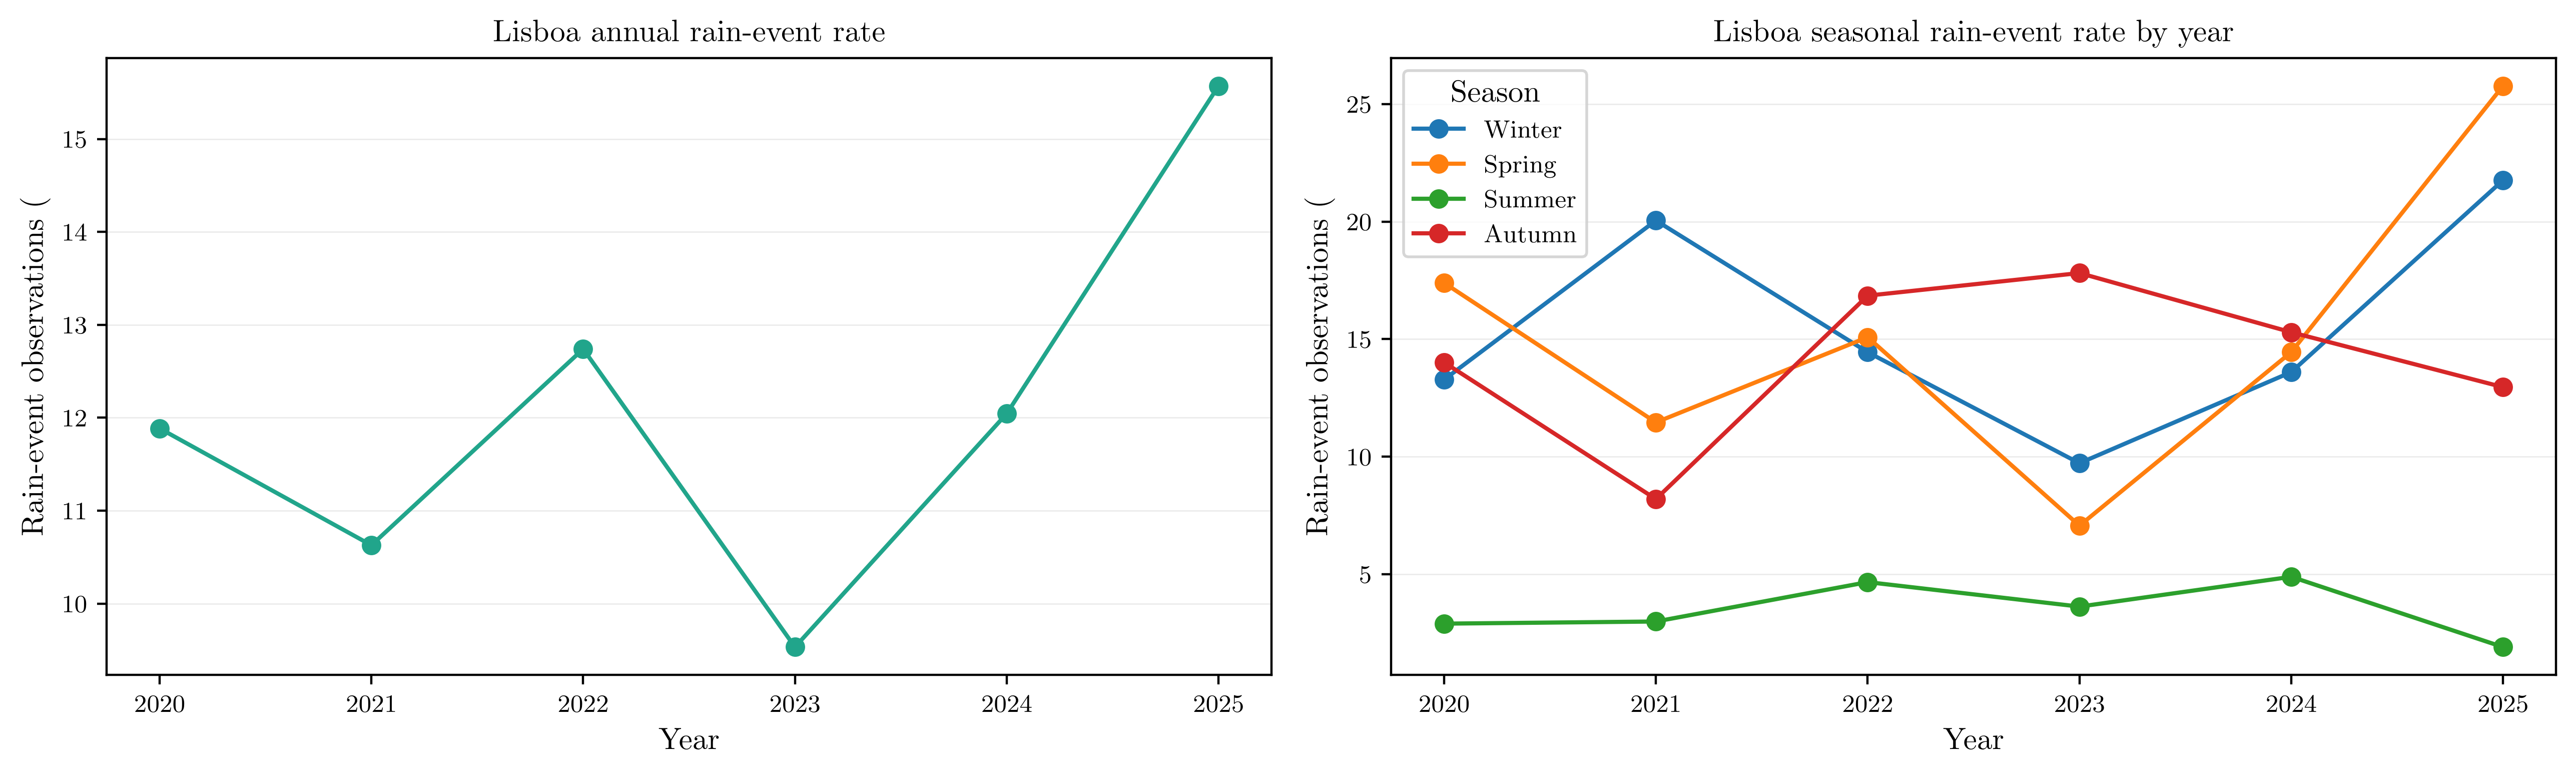

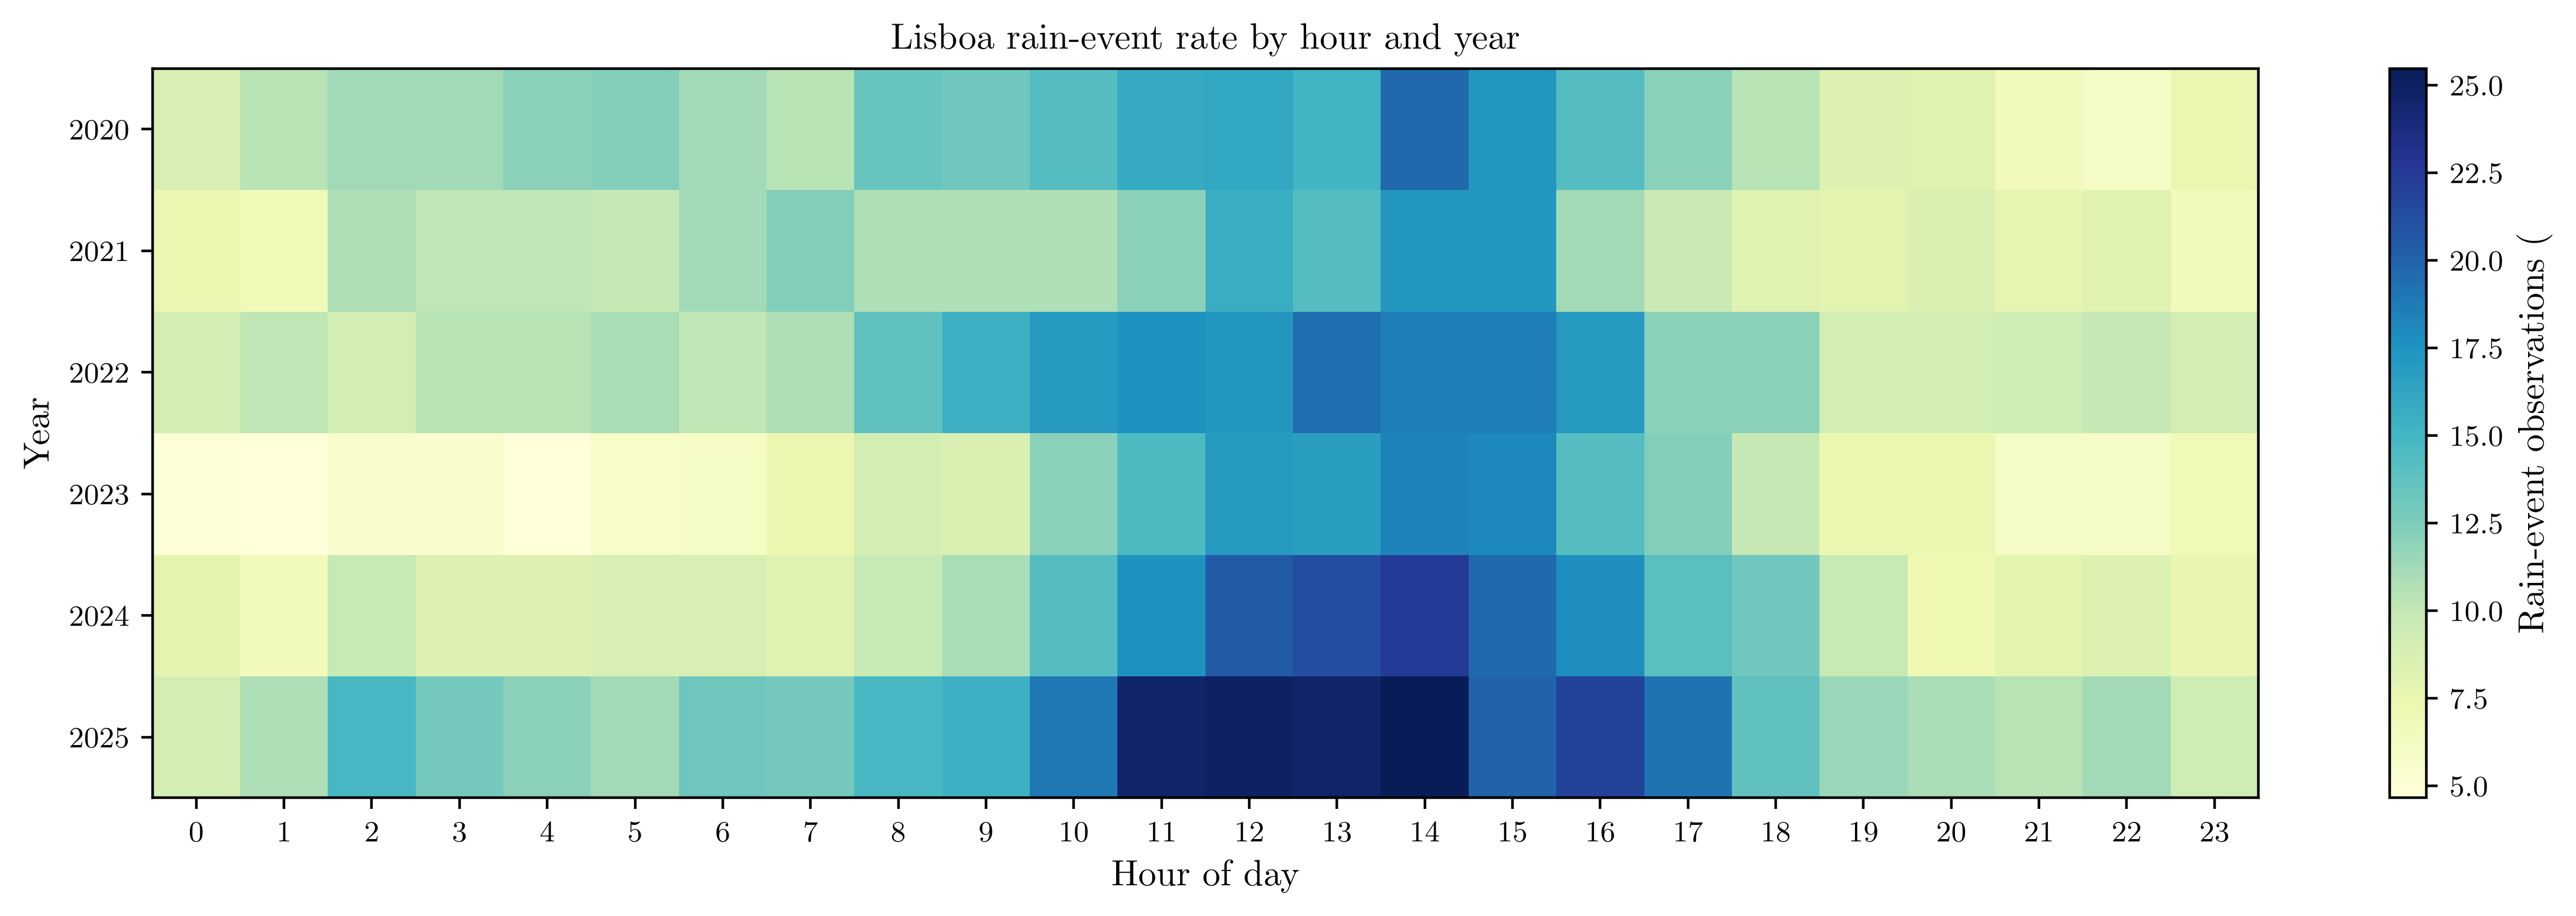

Peak rain-event hour by year:


,peak_hour
year,
2020,14
2021,14
2022,13
2023,14
2024,14
2025,14


In [132]:
# Compare annual/seasonal rates and inspect whether hour-of-day patterns repeat by year.
season_by_month = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn",
}
temporal_df = df.assign(
    year=df["time"].dt.year,
    season=df["time"].dt.month.map(season_by_month),
    hour=df["time"].dt.hour,
)
annual_rate = temporal_df.groupby("year")["rain_event"].mean().mul(100)
season_order = ["Winter", "Spring", "Summer", "Autumn"]
seasonal_rate = (
    temporal_df.groupby(["year", "season"])["rain_event"].mean().mul(100)
      .unstack("season")
      .reindex(columns=season_order)
)
display(pd.DataFrame({"annual_event_rate_pct": annual_rate}).round(2))
display(seasonal_rate.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
annual_rate.plot(marker="o", ax=axes[0], color="#21A58B")
axes[0].set(title="Lisboa annual rain-event rate", xlabel="Year", ylabel="Rain-event observations (%)")
seasonal_rate.plot(marker="o", ax=axes[1])
axes[1].set(title="Lisboa seasonal rain-event rate by year", xlabel="Year", ylabel="Rain-event observations (%)")
axes[1].legend(title="Season")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

hour_by_year = (
    temporal_df.groupby(["year", "hour"])["rain_event"].mean().mul(100)
      .unstack("hour")
)
fig, ax = plt.subplots(figsize=(12, 4))
image = ax.imshow(hour_by_year.values, aspect="auto", cmap="YlGnBu", interpolation="nearest")
ax.set(title="Lisboa rain-event rate by hour and year", xlabel="Hour of day", ylabel="Year")
ax.set_xticks(range(24))
ax.set_yticks(range(len(hour_by_year.index)), labels=hour_by_year.index)
fig.colorbar(image, ax=ax, label="Rain-event observations (%)")
fig.tight_layout()
plt.show()

peak_hour_each_year = hour_by_year.idxmax(axis=1)
print("Peak rain-event hour by year:")
display(peak_hour_each_year.rename("peak_hour").to_frame())

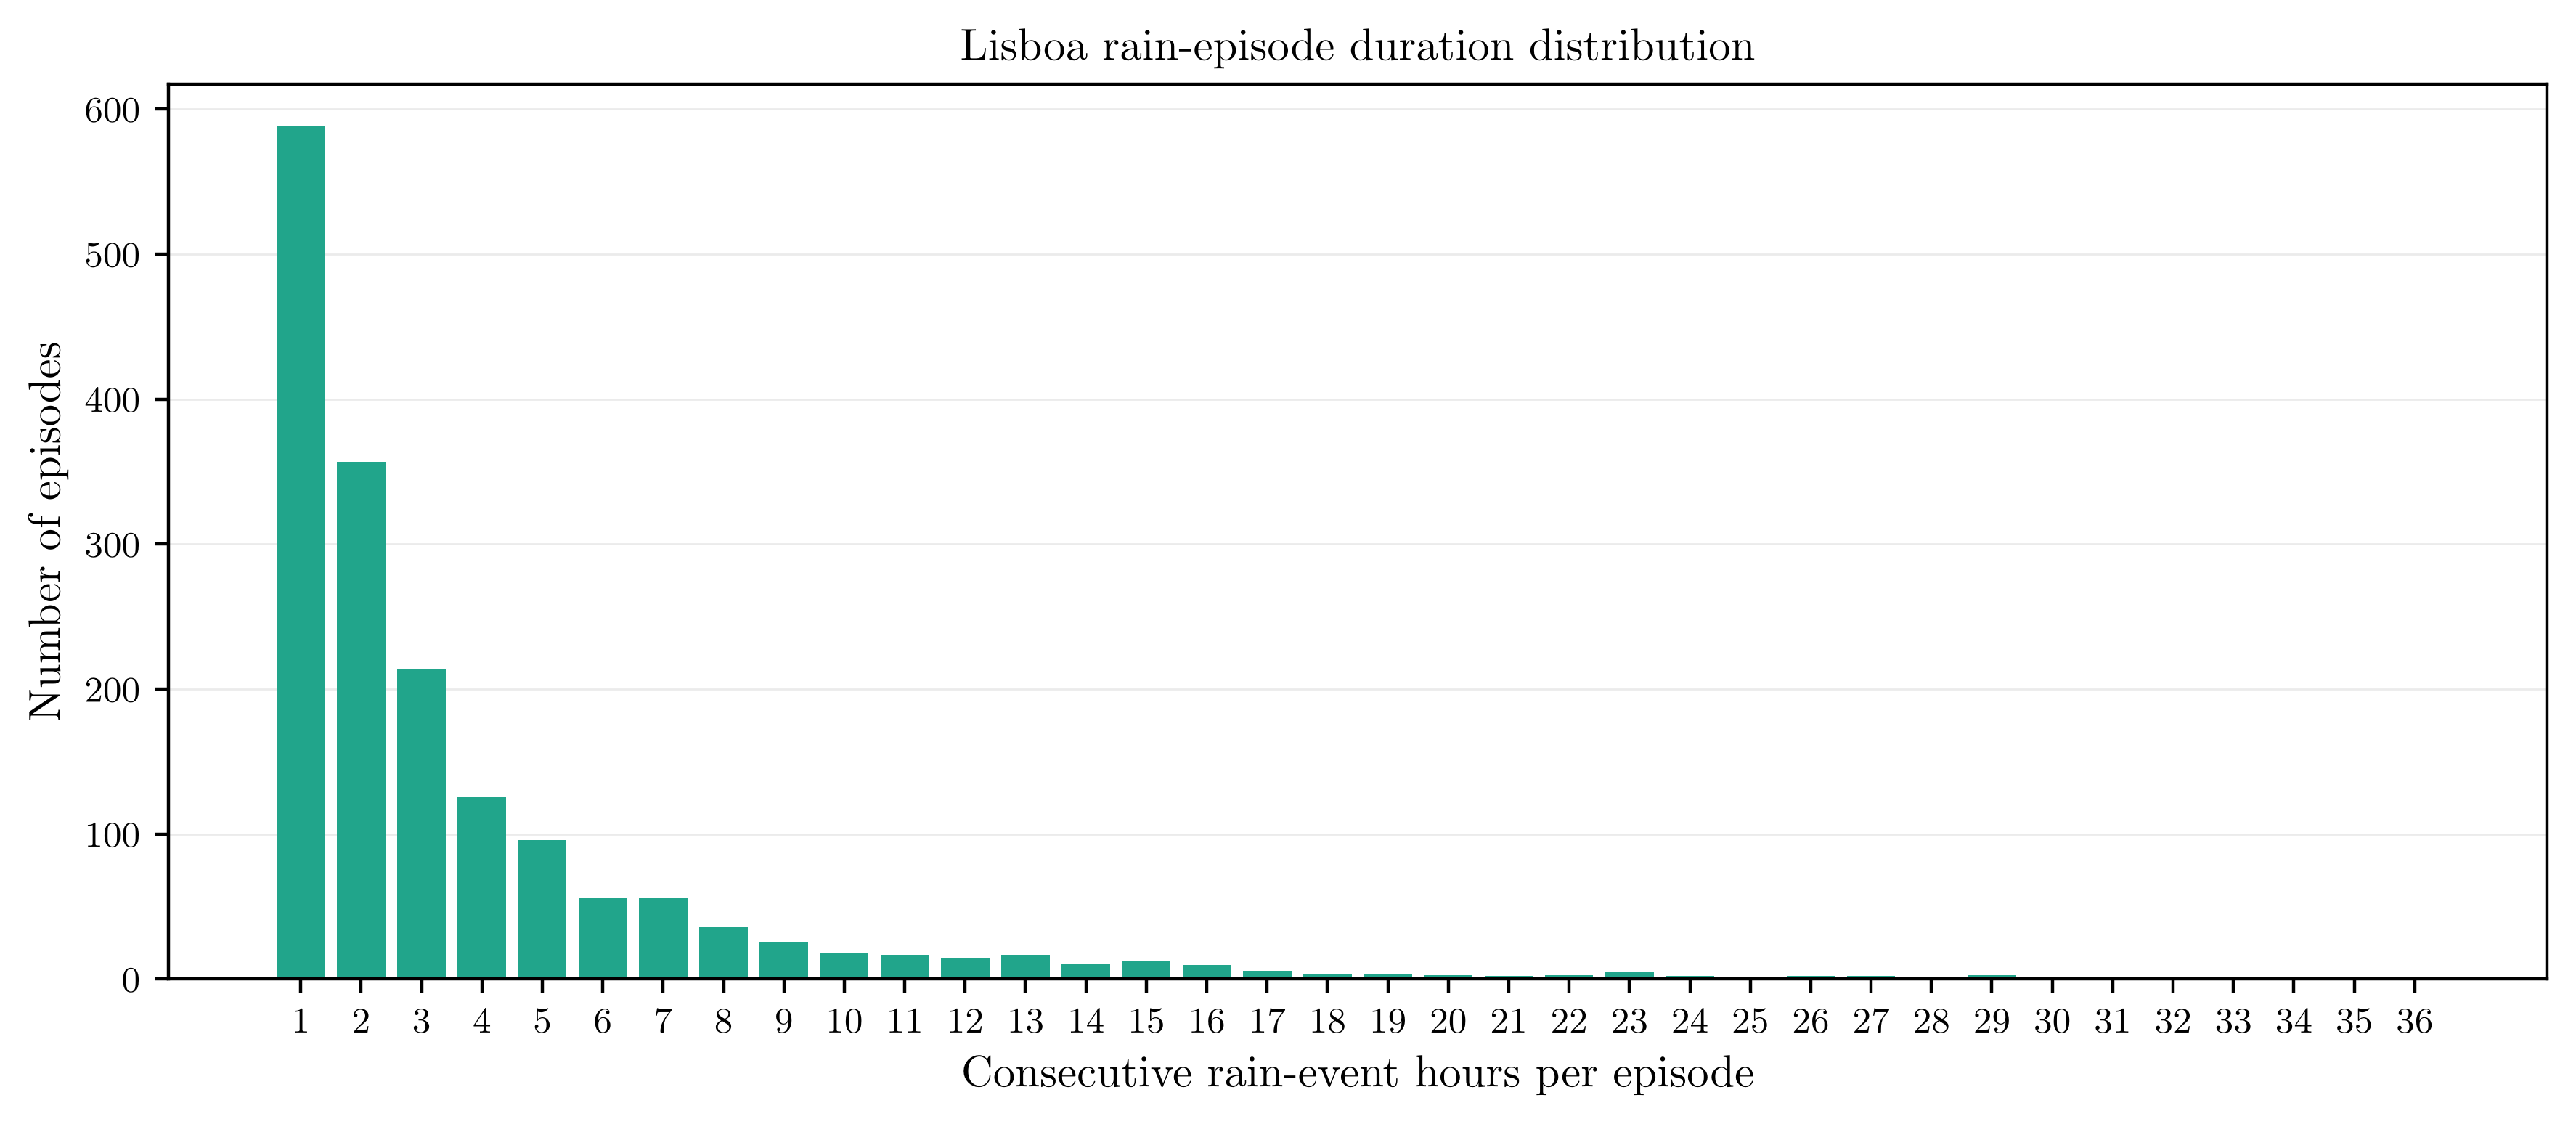

In [133]:
# A discrete duration-frequency plot complements the episode summary statistics above.
episode_duration_counts = rain_episode_hours.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(episode_duration_counts.index, episode_duration_counts.values, color="#21A58B")
ax.set(
    title="Lisboa rain-episode duration distribution",
    xlabel="Consecutive rain-event hours per episode",
    ylabel="Number of episodes",
)
ax.set_xticks(range(1, int(episode_duration_counts.index.max()) + 1))
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

,model,representation,accuracy,macro_f1,precision,recall,prediction_ms_per_event,update_ms_per_event
0,adaptive_random_forest,A,0.925311,0.799171,0.741636,0.562878,0.032417,0.153751
1,gaussian_naive_bayes,A,0.921556,0.753658,0.849747,0.406892,0.111920,0.004606
2,hoeffding_tree,A,0.935034,0.838013,0.744999,0.682991,0.004691,0.008582
3,online_bagging,A,0.935414,0.842530,0.734000,0.709593,0.031461,0.054019
4,online_logistic_regression,A,0.925264,0.774646,0.834930,0.456671,0.001900,0.004695
5,adaptive_random_forest,B,0.923172,0.793711,0.728836,0.555220,0.041644,0.240588
6,gaussian_naive_bayes,B,0.916278,0.772294,0.697044,0.513301,0.090168,0.005116
7,hoeffding_tree,B,0.933322,0.839230,0.719074,0.713422,0.010116,0.030930
8,online_bagging,B,0.935081,0.841606,0.732930,0.707376,0.059988,0.171142
9,online_logistic_regression,B,0.927522,0.794032,0.795307,0.519146,0.003253,0.009031


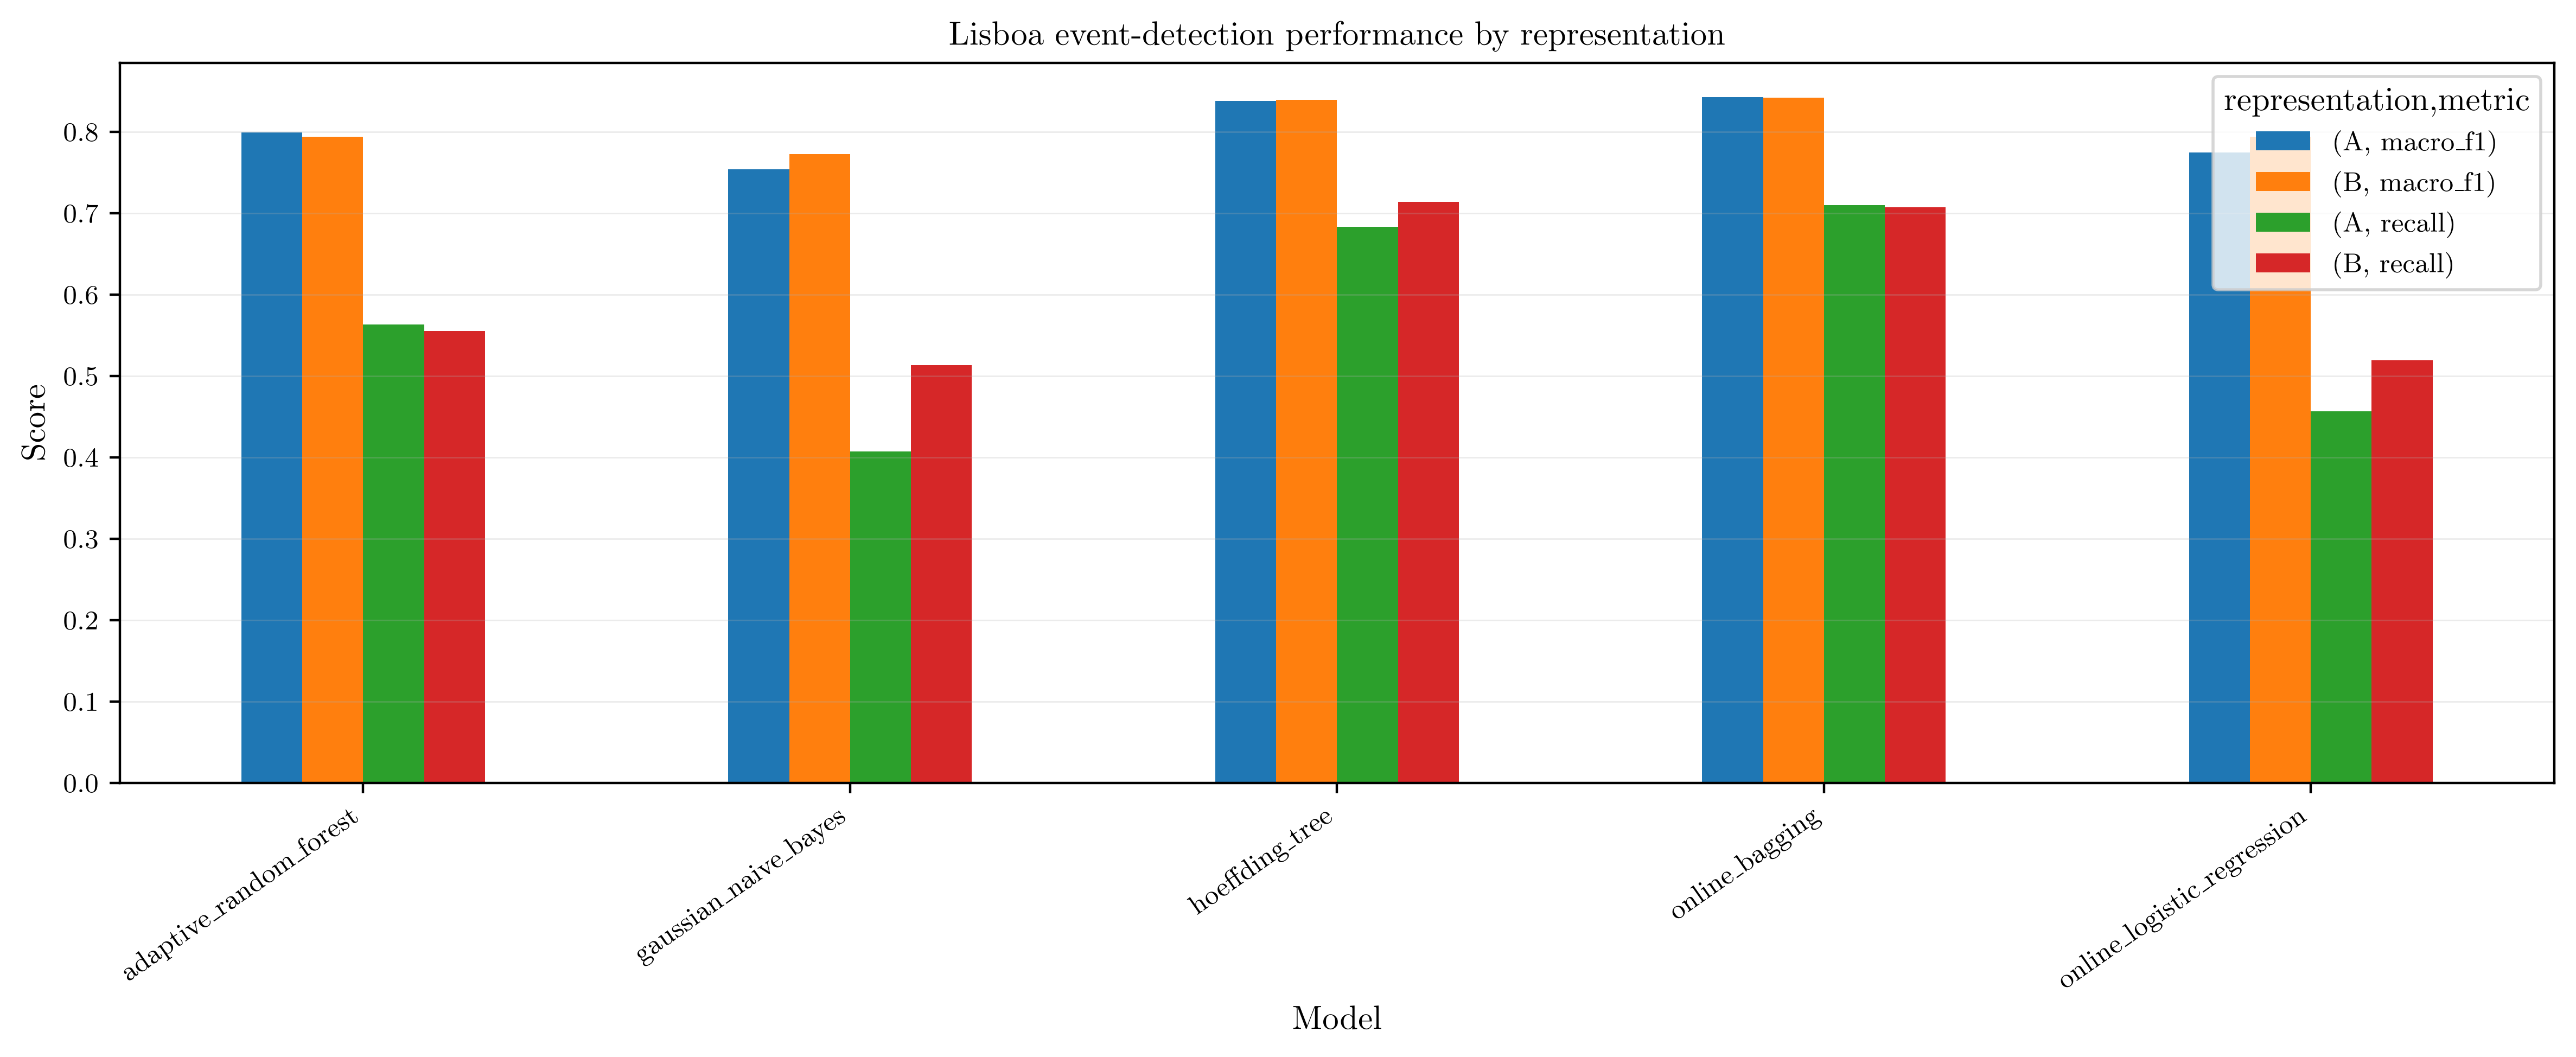

In [134]:
# Show only Lisboa experiment rows; the shared runner creates this CSV after execution.
experiment_config = config.get("experiment", {})
results_directory = experiment_config.get("results_directory", "results")
results_path = project_root / results_directory / "model_results.csv"
if not results_path.exists():
    print(f"Model results are not available yet: {results_path}")
    print("Run the shared experiment with `python main.py`, then rerun this cell.")
else:
    experiment_results = pd.read_csv(results_path)
    lisboa_results = experiment_results.loc[experiment_results["city"].eq(city)].copy()
    required_metrics = ["accuracy", "macro_f1", "precision", "recall", "prediction_ms_per_event", "update_ms_per_event"]
    lisboa_results = lisboa_results[["model", "representation", *required_metrics]]
    display(lisboa_results.sort_values(["representation", "model"]).reset_index(drop=True))

    metric_plot = lisboa_results.melt(
        id_vars=["model", "representation"],
        value_vars=["macro_f1", "recall"],
        var_name="metric",
        value_name="score",
    )
    score_plot = metric_plot.pivot(index="model", columns=["representation", "metric"], values="score")
    score_plot.plot(kind="bar", figsize=(12, 5))
    plt.title("Lisboa event-detection performance by representation")
    plt.ylabel("Score")
    plt.xlabel("Model")
    plt.xticks(rotation=35, ha="right")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()